In [1]:
from pathlib import Path 
from io import StringIO 
import subprocess 

import pandas as pd 
import matplotlib.pyplot as plt 

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent 

FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def load_sql_results(sql_file: str) -> pd.DataFrame: 
    result = subprocess.run(
        [
            "psql",
            "-X",
            "--csv",
            "-q",
            "-U", "postgres",
            "-h", "127.0.0.1",
            "-p", "5432",
            "-d", "olist_ecommerce",
            "-v", "ON_ERROR_STOP=1",
            "-f", str(PROJECT_ROOT / sql_file),
        ],
        capture_output=True,
        text=True,
        check=True,
    )

    return pd.read_csv(StringIO(result.stdout))



segments = load_sql_results(
    "sql/analysis/01_delivery_delay_vs_reviews.sql"
)

daily = load_sql_results(
    "sql/analysis/02_daily_delay_pattern.sql"
)

display(segments)
display(daily.head())

,delay_segment,reviewed_orders,avg_review_score,low_review_pct,five_star_pct
0,Early,87994,4.30,9.19,62.50
1,On time,1273,4.04,12.33,50.75
2,1-3 days late,1850,3.29,32.16,33.19
3,4-7 days late,1745,2.10,67.62,14.10
4,8-14 days late,1443,1.67,80.25,6.86
5,15+ days late,1330,1.72,78.35,7.22


,delivery_delay_days,reviewed_orders,avg_review_score,low_review_pct,five_star_pct
0,-5,2204,4.20,10.75,58.44
1,-4,1899,4.15,10.95,55.82
2,-3,1711,4.12,10.87,54.47
3,-2,1537,4.13,11.65,55.43
4,-1,1447,4.16,10.99,55.63


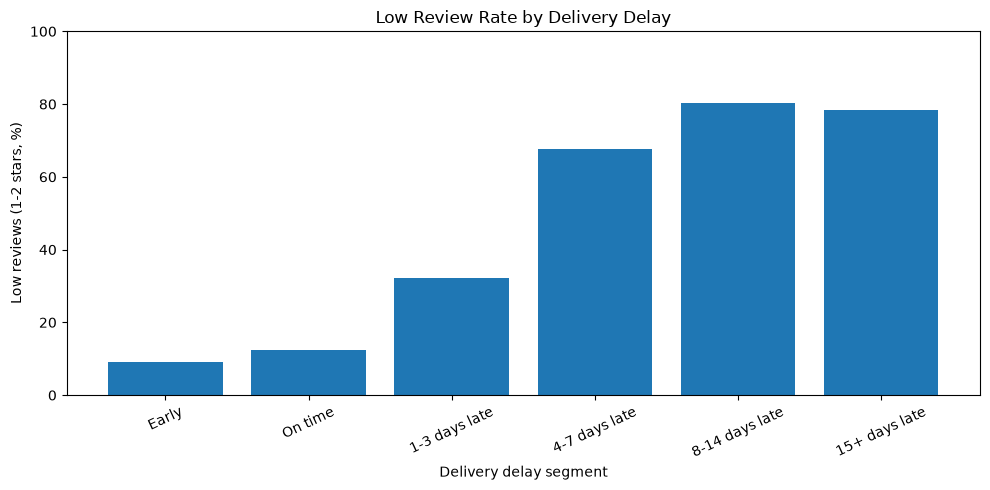

In [2]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    segments["delay_segment"],
    segments["low_review_pct"]
)

ax.set(
    title="Low Review Rate by Delivery Delay",
    xlabel="Delivery delay segment",
    ylabel="Low reviews (1-2 stars, %)",
    ylim=(0, 100)
)

ax.tick_params(axis="x", rotation=25)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "delay_segment_low_reviews.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

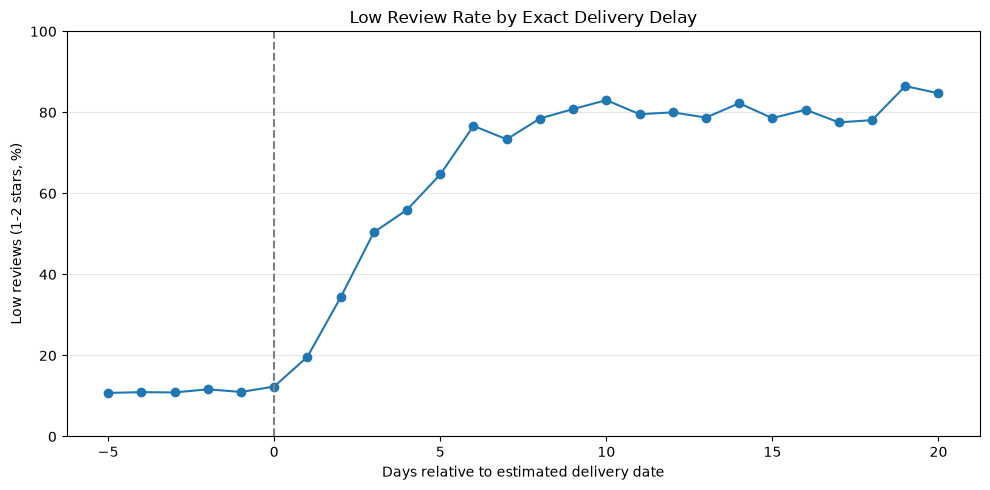

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    daily["delivery_delay_days"],
    daily["low_review_pct"],
    marker="o"
)

ax.axvline(0, linestyle="--", color="gray")

ax.set(
    title="Low Review Rate by Exact Delivery Delay",
    xlabel="Days relative to estimated delivery date",
    ylabel="Low reviews (1-2 stars, %)",
    ylim=(0, 100)
)

ax.grid(axis="y", alpha=0.3)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "daily_delay_low_reviews.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [4]:
estimate_summary = load_sql_results(
    "sql/analysis/03_delivery_estimate_accuracy.sql"
)

estimate_distribution = load_sql_results(
    "sql/analysis/04_delivery_estimate_distribution.sql"
)

display(estimate_summary)
display(estimate_distribution.describe())

,delivered_orders,avg_promised_days,avg_actual_days,avg_delivery_delay_days,avg_early_days,early_delivery_pct,on_time_pct,late_delivery_pct
0,96470,24.37,12.5,-11.88,-13.71,91.89,1.34,6.77


,delivery_delay_days,order_count
count,198.000000,198.000000
mean,21.464646,487.222222
std,70.482213,1241.046934
min,-147.000000,1.000000
25%,-32.750000,1.000000
50%,16.500000,8.000000
75%,68.750000,166.000000
max,188.000000,7126.000000


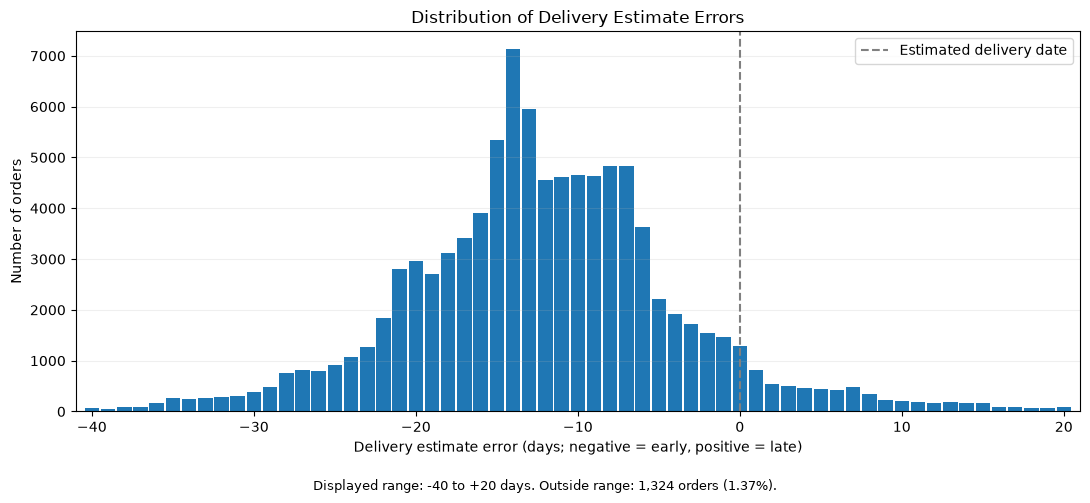

In [5]:
distribution = estimate_distribution 

visible_min = -40
visible_max = 20 

visible = distribution[
    distribution["delivery_delay_days"].between(
        visible_min, visible_max 
    )
]

excluded_orders = (
    distribution.loc[
        ~distribution["delivery_delay_days"].between(
            visible_min, visible_max
        ),
        "order_count"
    ].sum()
)

total_orders = distribution["order_count"].sum()
excluded_pct = excluded_orders / total_orders * 100

fig, ax = plt.subplots(figsize=(11, 5))

ax.bar(
    visible["delivery_delay_days"],
    visible["order_count"],
    width=0.9
)

ax.axvline(
    x=0,
    color="gray",
    linestyle="--",
    linewidth=1.5,
    label="Estimated delivery date"
)

ax.set(
    title="Distribution of Delivery Estimate Errors",
    xlabel="Delivery estimate error (days; negative = early, positive = late)",
    ylabel="Number of orders",
    xlim=(visible_min - 1, visible_max + 1)
)

ax.legend()
ax.grid(axis="y", alpha=0.2)

fig.text(
    0.5, 0.01,
    (
        f"Displayed range: {visible_min} to +{visible_max} days. "
        f"Outside range: {excluded_orders:,} orders "
        f"({excluded_pct:.2f}%)."
    ),
    ha="center",
    fontsize=9
)

fig.tight_layout(rect=(0, 0.05, 1, 1))

fig.savefig(
    FIGURES_DIR / "delivery_estimate_error_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [6]:
state_performance = load_sql_results(
    "sql/analysis/05_delivery_performance_by_state.sql"
)

display(state_performance)

,customer_state,delivered_orders,late_orders,late_delivery_pct,avg_delivery_days,avg_estimate_error_days,reviewed_orders,avg_review_score,low_review_pct
0,AL,397,85,21.41,24.50,-8.71,393,3.85,21.12
1,MA,717,125,17.43,21.51,-9.57,711,3.83,19.97
2,SE,335,51,15.22,21.46,-10.02,334,3.91,18.86
3,PI,476,66,13.87,19.39,-11.31,471,3.99,16.14
4,CE,1279,176,13.76,21.20,-10.80,1271,3.94,17.15
5,RR,41,5,12.20,29.34,-17.29,41,3.90,14.63
6,BA,3256,396,12.16,19.28,-10.79,3222,3.93,16.98
7,RJ,12350,1495,12.11,15.24,-11.76,12175,3.97,18.30
8,PA,946,106,11.21,23.73,-14.07,931,3.91,17.94
9,ES,1995,214,10.73,15.72,-10.50,1967,4.08,13.78


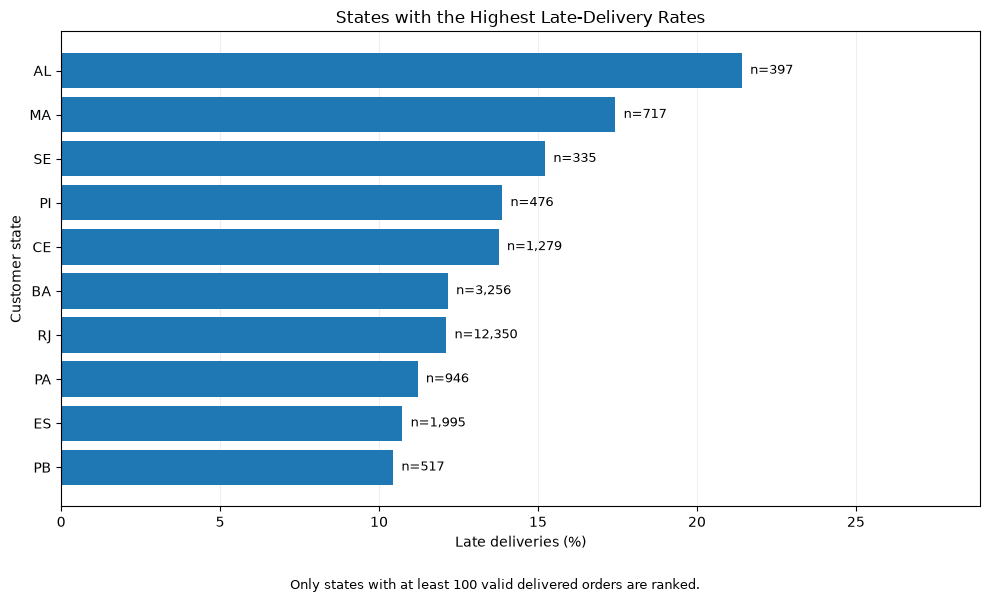

In [7]:
# Restrict the ranking to states with sufficient observations.
MIN_ORDERS = 100

top_states = (
    state_performance
    .loc[
        state_performance["delivered_orders"] >= MIN_ORDERS 
    ]
    .nlargest(10, "late_delivery_pct")
    .sort_values("late_delivery_pct")
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    top_states["customer_state"],
    top_states["late_delivery_pct"]
)

ax.set(
    title="States with the Highest Late-Delivery Rates",
    xlabel="Late deliveries (%)",
    ylabel="Customer state"
)

# Display sample sizes beside the bars.
for bar, order_count in zip(
    bars,
    top_states["delivered_orders"]
):
    ax.annotate(
        f"n={order_count:,}",
        xy=(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        fontsize=9
    )

ax.set_xlim(
    0,
    top_states["late_delivery_pct"].max() * 1.35
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.5, 0.01,
    f"Only states with at least {MIN_ORDERS} "
    "valid delivered orders are ranked.",
    ha="center",
    fontsize=9
)

fig.tight_layout(rect=(0, 0.05, 1, 1))

fig.savefig(
    FIGURES_DIR / "late_delivery_rate_by_state.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [8]:
delivery_windows = load_sql_results(
    "sql/analysis/06_delivery_windows_by_state.sql"
)

display(delivery_windows.head())

,customer_state,delivered_orders,avg_promised_days,avg_actual_days,avg_estimate_error_days,late_delivery_pct
0,SP,40494,19.78,8.70,-11.08,4.49
1,RJ,12350,27.00,15.24,-11.76,12.11
2,MG,11354,25.19,11.94,-13.24,4.57
3,RS,5344,29.16,15.25,-13.91,6.08
4,PR,4923,25.25,11.94,-13.31,4.04


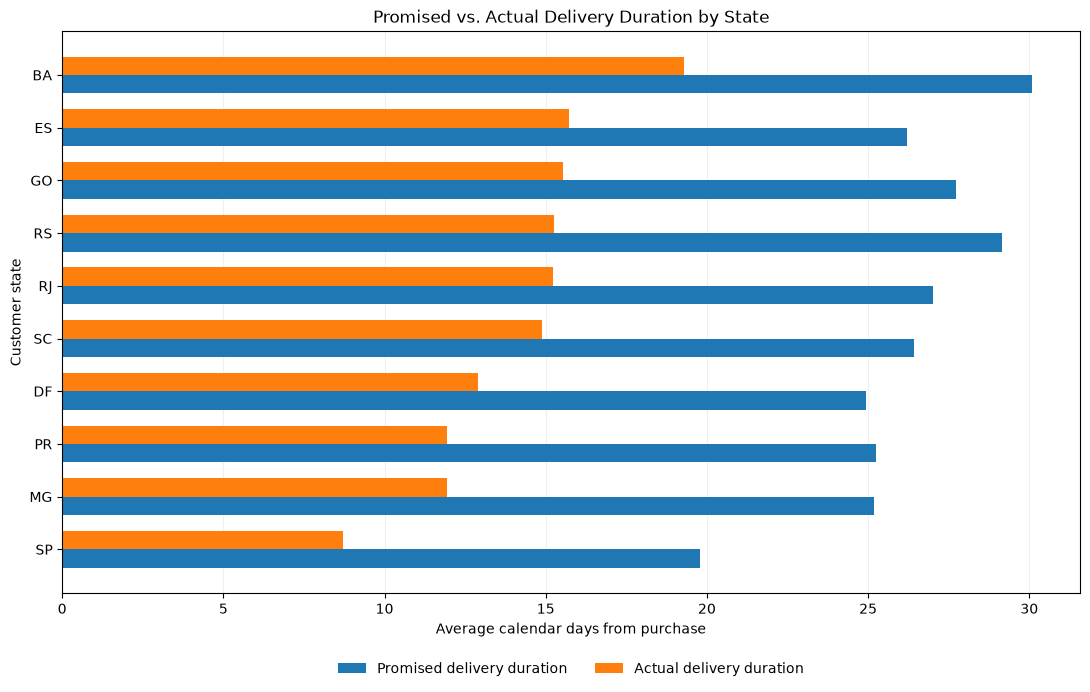

In [9]:
# Top 10 customer states by delivered order volume
top_states = (
    delivery_windows
    .nlargest(10, "delivered_orders")
    .sort_values("avg_actual_days")
)

fig, ax = plt.subplots(figsize=(11, 7))

y = range(len(top_states))
bar_height = 0.35

ax.barh(
    [pos - bar_height / 2 for pos in y],
    top_states["avg_promised_days"],
    height=bar_height,
    label="Promised delivery duration"
)

ax.barh(
    [pos + bar_height / 2 for pos in y],
    top_states["avg_actual_days"],
    height=bar_height,
    label="Actual delivery duration"
)

ax.set_yticks(list(y))
ax.set_yticklabels(top_states["customer_state"])

ax.set(
    title="Promised vs. Actual Delivery Duration by State",
    xlabel="Average calendar days from purchase",
    ylabel="Customer state"
)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=2,
    frameon=False
)
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "delivery_windows_by_state.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


In [10]:
interstate = load_sql_results(
    "sql/analysis/08_interstate_delivery_performance.sql"
)

display(interstate)

,population,shipping_type,delivered_orders,avg_promised_days,avg_actual_days,avg_estimate_error_days,late_delivery_pct,seven_plus_days_late_pct
0,All states,Interstate,60961,27.82,15.15,-12.67,8.14,4.56
1,All states,Same-state,34234,18.17,7.90,-10.27,4.56,1.65
2,RJ only,Interstate,11251,27.60,16.03,-11.57,12.84,8.46
3,RJ only,Same-state,943,19.59,6.54,-13.05,4.77,2.01


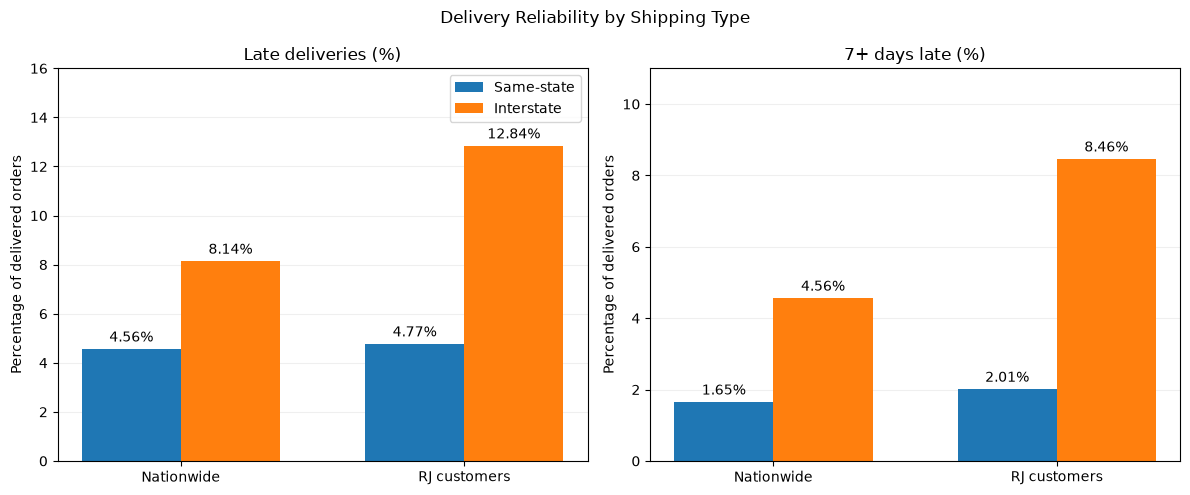

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

metrics = [
    ("late_delivery_pct", "Late deliveries (%)"),
    ("seven_plus_days_late_pct", "7+ days late (%)")
]

populations = ["All states", "RJ only"]
shipping_types = ["Same-state", "Interstate"]

for ax, (metric, title) in zip(axes, metrics):
    for i, shipping_type in enumerate(shipping_types):
        values = [
            interstate.loc[
                (interstate["population"] == population)
                & (interstate["shipping_type"] == shipping_type),
                metric 
            ].iloc[0]
            for population in populations
        ]

        positions = [x + (i - 0.5) * 0.35 for x in range(2)]

        bars = ax.bar(
            positions,
            values,
            width=0.35,
            label=shipping_type 
        )

        ax.bar_label(bars, fmt="%.2f%%", padding=3)

    ax.set_xticks(range(2))
    ax.set_xticklabels(["Nationwide", "RJ customers"])
    ax.set_title(title)
    ax.set_ylabel("Percentage of delivered orders")
    ax.set_ylim(0, 16 if metric == "late_delivery_pct" else 11)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

axes[0].legend()

fig.suptitle("Delivery Reliability by Shipping Type")
fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "interstate_delivery_performance.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [12]:

rj_origins = load_sql_results(
    "sql/analysis/09_rj_shipping_origins.sql"
)

display(rj_origins)

print(
    "Total RJ single-seller deliveries:",
    rj_origins["delivered_orders"].sum()
)


,origin_state,shipping_type,delivered_orders,late_orders,late_delivery_pct,seven_plus_days_late_orders,seven_plus_days_late_pct,avg_promised_days,avg_actual_days,avg_estimate_error_days
0,SP,Interstate,8048,1147,14.25,761,9.46,27.02,16.27,-10.74
1,PR,Interstate,951,117,12.30,76,7.99,30.30,17.33,-12.97
2,MG,Interstate,1124,94,8.36,57,5.07,27.46,14.19,-13.27
3,RJ,Same-state,943,45,4.77,19,2.01,19.59,6.54,-13.05
4,SC,Interstate,465,43,9.25,29,6.24,29.80,16.42,-13.38
5,RS,Interstate,240,17,7.08,10,4.17,29.15,14.10,-15.05
6,DF,Interstate,96,7,7.29,5,5.21,29.57,13.89,-15.69
7,ES,Interstate,59,5,8.47,3,5.08,24.08,12.58,-11.51
8,BA,Interstate,83,4,4.82,3,3.61,26.98,13.28,-13.70
9,GO,Interstate,56,3,5.36,3,5.36,30.25,14.57,-15.68


Total RJ single-seller deliveries: 12194


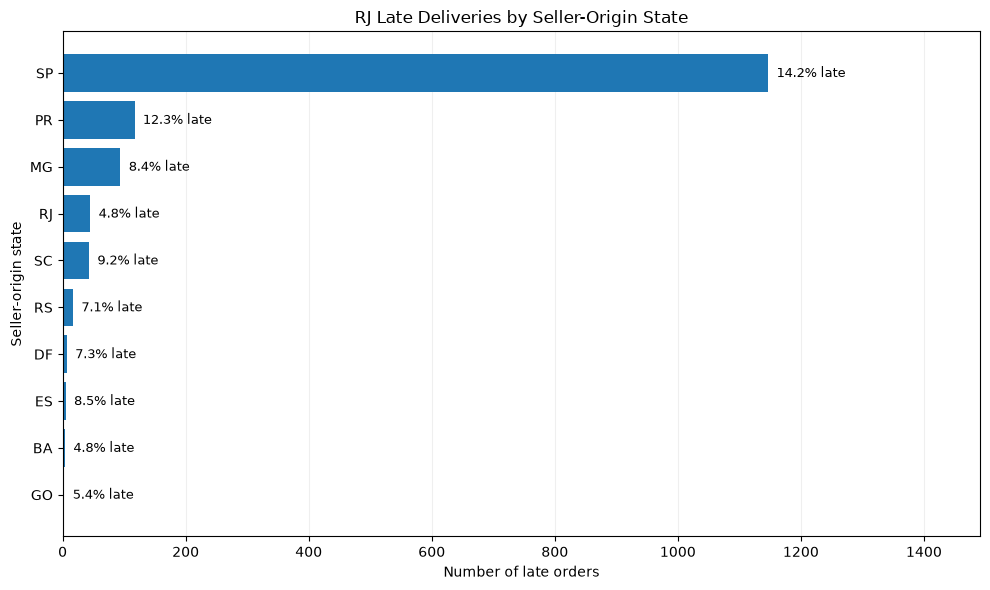

In [13]:

# Rank origins by absolute number of late deliveries.
top_origins = (
    rj_origins
    .nlargest(10, "late_orders")
    .sort_values("late_orders")
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    top_origins["origin_state"],
    top_origins["late_orders"]
)

# Show the late-delivery rate beside each origin.
for bar, rate in zip(
    bars,
    top_origins["late_delivery_pct"]
):
    ax.annotate(
        f"{rate:.1f}% late",
        xy=(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        fontsize=9
    )

ax.set(
    title="RJ Late Deliveries by Seller-Origin State",
    xlabel="Number of late orders",
    ylabel="Seller-origin state"
)

ax.set_xlim(
    0,
    top_origins["late_orders"].max() * 1.3
)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "rj_late_deliveries_by_origin.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
